In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from random import randint
import torch
from torch import nn

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/model/rnn_loader.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from model.rnn_loader import load_rnn_model, checkpoint_parameters
from model.training.train import read_csv, prepare_sequences
from model.export_rnn import export_onnx
DATA_DIR = PROJECT_ROOT / "data/generated_data"
MAX_TRAJECTORIES = None  # Set an integer for a quick data/evaluation check.

from policy.lib.droneEnv import PARAMS
MODEL_PATH = PROJECT_ROOT / "src/model/checkpoints/rnn_z.pt"
ONNX_PATH = MODEL_PATH.with_suffix(".onnx")
model = load_rnn_model(MODEL_PATH)
params = checkpoint_parameters(model, PARAMS, "z")
INPUT_FILE = PROJECT_ROOT / "data/initial_data/bdd_in_mat_05.csv"
OUTPUT_FILE = PROJECT_ROOT / "data/initial_data/bdd_out_mat_05.csv"
data_in, data_out = prepare_sequences(read_csv(INPUT_FILE, MAX_TRAJECTORIES),
    read_csv(OUTPUT_FILE, MAX_TRAJECTORIES), "z", "controls", "selected")
nb_data = len(data_in)


In [2]:
train_size = int(0.7 * nb_data)
val_size = int(0.15 * nb_data)
test_size = nb_data - train_size - val_size
az_data = (data_out[..., 0] - params.mean_az) / params.sigma_az
input_data = (data_in[..., 0] - params.mean_u) / params.sigma_u


In [9]:
import onnx
import onnxruntime
if not ONNX_PATH.is_file():
    export_onnx(model, ONNX_PATH)
onnx.checker.check_model(onnx.load(str(ONNX_PATH)))


Text(0.5, 1.0, 'Error')

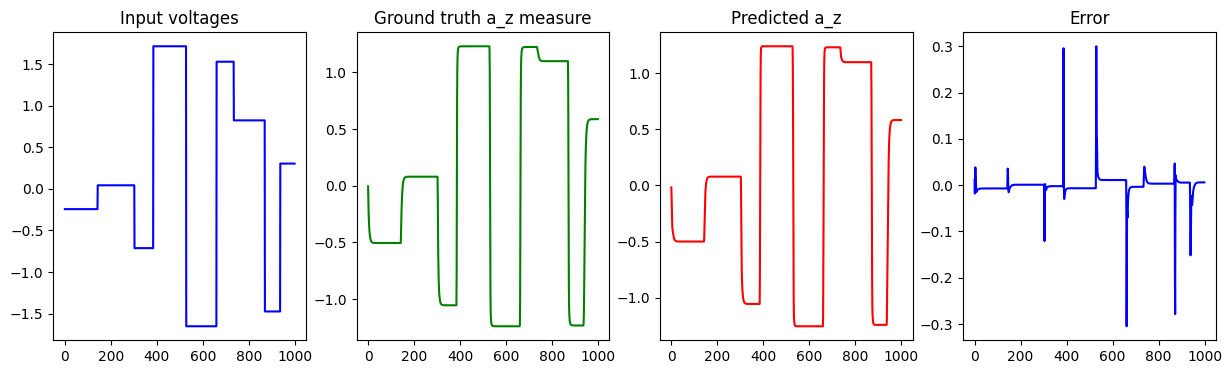

In [22]:
onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)

ort_session = onnxruntime.InferenceSession(
    str(str(ONNX_PATH)), providers=["CPUExecutionProvider"]
)

input_names = [inp.name for inp in ort_session.get_inputs()]
x_name = input_names[0]
h_name = input_names[1]

train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)

full_sequence = input_data[test_rand_idx].reshape(1, -1, 1).astype(np.float32)

hidden_size = model.rnn.hidden_size
h = np.zeros((1, 1, hidden_size), dtype=np.float32)

onnxruntime_outputs_list = []

for t in range(full_sequence.shape[1]):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = ort_session.run(
        None, 
        {x_name: x_step, h_name: h}
    )
    onnxruntime_outputs_list.append(out)

onnxruntime_outputs = np.concatenate(onnxruntime_outputs_list, axis=1)

fig, axes = plt.subplots(1, 4)
fig.set_figheight(4)
fig.set_figwidth(15)
axes[0].plot(input_data[test_rand_idx].reshape(-1), c="blue")
axes[0].set_title("Input voltages")
axes[1].plot(az_data[test_rand_idx], c="green")
axes[1].set_title("Ground truth a_z measure")
axes[2].plot(onnxruntime_outputs[:, :][0], c="red")
axes[2].set_title("Predicted a_z")
axes[3].plot(az_data[test_rand_idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")
axes[3].set_title("Error")